In [56]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal


# Sorry for the typos in advance

print("Installations Working!")

Installations Working!


# Data Setup

In [57]:
# Parameter Definitions

class_1_prior = .3
class_2_prior = .3
class_3_prior = .4

# Set Random Seed
rng = np.random.default_rng(1)

dist_1_mu = [1, 1, 1]
dist_2_mu = [1, -1, -1]
dist_3_mu = [-1, 1, -1]
dist_4_mu = [-1, -1, 1]


# Quick verification of mean equidistance
mu_list = [dist_1_mu, dist_2_mu, dist_3_mu, dist_4_mu]


dist_1_cov = [[2,   -1.5, .5],
              [-1.5, 2, 1],
              [.5, 1, 5]]

dist_2_cov = [[1,   -.2, -.5],
              [-.2, 2, .5],
              [-.5, .5, 1.5]]

dist_3_cov = [[1, .1, .5],
              [.1, 1.5, 1],
              [.5, 1, 1.5]]

dist_4_cov = [[2, .1, .5],
              [.1, 2, .1],
              [.5, .1, .5]]

cov_list = [dist_1_cov, dist_2_cov, dist_3_cov, dist_4_cov]

# average standard deviation across all components
all_stds = [np.sqrt(np.diag(np.array(C))) for C in cov_list]
avg_std = np.mean(all_stds)
print(f"Average std: {avg_std:.4f}")

# distance / avg_std for every pair
for i in range(len(mu_list)):
    for j in range(i + 1, len(mu_list)):
        d = np.linalg.norm(np.array(mu_list[i]) - np.array(mu_list[j]))
        print(f"mu_{i+1} to mu_{j+1}: distance = {d:.3f}, ratio = {d / avg_std:.2f}")


L = (rng.random(10000) < .3).astype(int)   # 1 with prob 0.65, else 0
n1 = np.sum(L == 1)

n0 = np.sum(L == 0)
L = (rng.random(n0) < (.3/.7)).astype(int)
n2 = np.sum(L == 1)
n3 = np.sum(L == 0)

dist_1 = rng.multivariate_normal(dist_1_mu, dist_1_cov, size=n1)
dist_2 = rng.multivariate_normal(dist_2_mu, dist_2_cov, size=n2)
dist_3 = rng.multivariate_normal(dist_3_mu, dist_3_cov, size=int(n3/2))
dist_4 = rng.multivariate_normal(dist_4_mu, dist_4_cov, size=int(n3/2)+1)

X_dist = np.vstack([dist_1, dist_2, dist_3, dist_4])
L = np.concatenate([np.full(n1, 1), np.full(n2, 2), np.full(n3, 3)])
# Verification

print(f"Dist: X_dist | Shape: {X_dist.shape}")
print(f"Mean: {np.mean(X_dist)} | {np.mean(X_dist[L == 1], axis=0)} | {np.mean(X_dist[L == 2], axis=0)} | {np.mean(X_dist[L == 3], axis=0)}")
print(f"Labels: {np.mean(L)} | Shape: {L.shape}")



print(f"Counts-- N1: {n1} | N2: {n2} | N3: {n3}")

Average std: 1.3074
mu_1 to mu_2: distance = 2.828, ratio = 2.16
mu_1 to mu_3: distance = 2.828, ratio = 2.16
mu_1 to mu_4: distance = 2.828, ratio = 2.16
mu_2 to mu_3: distance = 2.828, ratio = 2.16
mu_2 to mu_4: distance = 2.828, ratio = 2.16
mu_3 to mu_4: distance = 2.828, ratio = 2.16
Dist: X_dist | Shape: (10000, 3)
Mean: 0.06623971052317923 | [1.004787   0.99245048 0.97059489] | [ 1.03779876 -0.98037188 -1.02169687] | [-1.00088136e+00  3.46699145e-03  7.80014375e-04]
Labels: 2.0937 | Shape: (10000,)
Counts-- N1: 2990 | N2: 3083 | N3: 3927


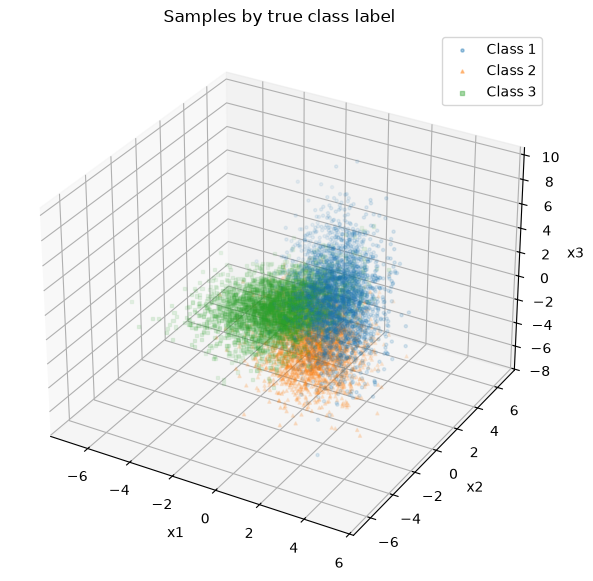

In [58]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection='3d')

markers = {1: 'o', 2: '^', 3: 's'}
colors  = {1: 'tab:blue', 2: 'tab:orange', 3: 'tab:green'}

for k in [1, 2, 3]:
    pts = X_dist[L == k]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
               marker=markers[k], c=colors[k], s=5, alpha=0.4,
               label=f"Class {k}")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")
ax.set_title("Samples by true class label")
ax.legend()
plt.show()

# Part A.2


In [68]:
# ERM Classifier


def g(mu, C):
    return multivariate_normal(mu, C).pdf(X_dist)

scores = np.stack([
    g(dist_1_mu, dist_1_cov) * class_1_prior,
    g(dist_2_mu, dist_2_cov) * class_2_prior,
    (0.5 * g(dist_3_mu, dist_3_cov) + 0.5 * g(dist_4_mu, dist_4_cov)) * class_3_prior,
], axis=1)

D = np.argmax(scores, axis=1) + 1     # decisions, 1/2/3


scores.shape

print(f"Accuracy: {np.mean(D == L)}")

Accuracy: 0.7871


In [67]:
Lambda = 1 - np.eye(3)          # 0-1 loss -> gives the same result as MAP
risks = scores @ Lambda.T        # shape (10000, 3): risk of each decision
D_erm = np.argmin(risks, axis=1) + 1

D_erm
print(f"Accuracy: {np.mean(D_erm == L)}")

Accuracy: 0.7871


In [61]:
conf = np.zeros((3, 3))
for i in [1, 2, 3]:
    for j in [1, 2, 3]:
        conf[i-1, j-1] = np.mean(D[L == j] == i)    # P(D=i | L=j)
print(np.round(conf, 3))

[[0.714 0.108 0.091]
 [0.155 0.779 0.06 ]
 [0.131 0.113 0.849]]


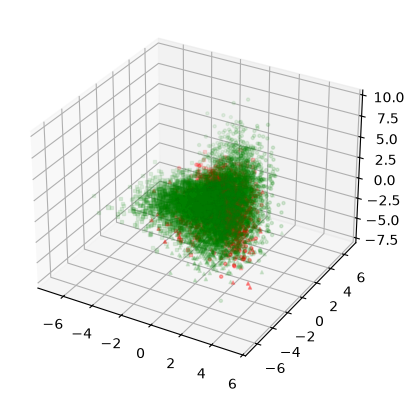

In [62]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
markers = {1: 'o', 2: '^', 3: 's'}
for k in [1, 2, 3]:
    correct = (L == k) & (D == k)
    wrong   = (L == k) & (D != k)
    ax.scatter(*X_dist[correct].T, marker=markers[k], c='green', s=5, alpha=0.4)
    ax.scatter(*X_dist[wrong].T,   marker=markers[k], c='red',   s=5, alpha=0.6)
plt.show()

# Part B

In [70]:
Lambda = 1 - np.eye(3)          # 0-1 loss -> gives the same result as MAP
risks = scores @ Lambda.T        # shape (10000, 3): risk of each decision
D_erm = np.argmin(risks, axis=1) + 1


print(f"Accuracy of 0-1 Loss : {np.mean(D_erm == L)}")
conf = np.zeros((3, 3))
for i in [1, 2, 3]:
    for j in [1, 2, 3]:
        conf[i-1, j-1] = np.mean(D_erm[L == j] == i)    # P(D=i | L=j)
print(np.round(conf, 3))

# 10 Times

Lambda_10 = np.array([[0, 0, 10], 
            [1, 0, 10], 
            [1, 1, 0 ]])


1 - np.eye(3)          # 0-1 loss -> gives the same result as MAP
risks = scores @ Lambda_10.T        # shape (10000, 3): risk of each decision
D_erm_10 = np.argmin(risks, axis=1) + 1

print(f"Accuracy: {np.mean(D_erm_10 == L)}")
conf = np.zeros((3, 3))
for i in [1, 2, 3]:
    for j in [1, 2, 3]:
        conf[i-1, j-1] = np.mean(D_erm_10[L == j] == i)    # P(D=i | L=j)
print(np.round(conf, 3))



# 100 Times

Lambda_100 = np.array([[0, 0, 100], 
              [1, 0, 100], 
              [1, 1, 0  ]])


1 - np.eye(3)          # 0-1 loss -> gives the same result as MAP
risks = scores @ Lambda_100.T        # shape (10000, 3): risk of each decision
D_erm_100 = np.argmin(risks, axis=1) + 1


print(f"Accuracy: {np.mean(D_erm_100 == L)}")
conf = np.zeros((3, 3))
for i in [1, 2, 3]:
    for j in [1, 2, 3]:
        conf[i-1, j-1] = np.mean(D_erm_100[L == j] == i)    # P(D=i | L=j)
print(np.round(conf, 3))



Accuracy of 0-1 Loss : 0.7871
[[0.714 0.108 0.091]
 [0.155 0.779 0.06 ]
 [0.131 0.113 0.849]]
Accuracy: 0.5479
[[0.543 0.671 0.019]
 [0.    0.    0.   ]
 [0.457 0.329 0.981]]
Accuracy: 0.4737
[[0.272 0.415 0.001]
 [0.    0.    0.   ]
 [0.728 0.585 0.999]]
